# T040 — Knowledge-tracing benchmark: results

**Ticket:** T040 (KK-60). **Decision record:** [ADR 0007](../../docs/architecture/decisions/0007-knowledge-tracing-model.md) (Proposed — the product owner decides).

This notebook reads the results saved by `kt_benchmark.py --mode full` and shows them as tables and charts. It trains nothing and runs in a few seconds. To reproduce the numbers, run the script (see [README](README.md)); the run logs every training run to MLflow with its seed, data source and code version.

**What is compared.** DKT (baseline), SAKT, SAINT and AKT from pyKT, and SAINT+ from `kuizi_brain` (pyKT has no SAINT+). All models have the same width (64), the same optimiser, the same windows and the same early stopping; no model was tuned individually.

**How.** Students are split into 5 folds with a fixed seed; three folds are run, each trained on the other students (10 % of them held out for early stopping) and tested on students the model has never seen. Every answer of a test student except the first is predicted exactly once, so all models are scored on the same predictions. Numbers are mean ± standard deviation over the three folds.

**Charts.** Each model has its own marker shape and line style, and values are written on the charts, so no chart relies on colour alone.

In [1]:
# Load the saved results (concept: reproducible benchmark, T040)
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MODE = "full"
candidates = [Path.cwd() / "results", Path.cwd() / "benchmarks" / "results", Path.cwd() / "ml" / "benchmarks" / "results"]
RESULTS = next(p for p in candidates if (p / f"t040_{MODE}_meta.json").exists())
read = lambda name: pd.read_csv(RESULTS / f"t040_{MODE}_{name}.csv")
meta = json.loads((RESULTS / f"t040_{MODE}_meta.json").read_text())
runs, slices, calib, latency, gate, history = (read(n) for n in ("runs", "slices", "calibration", "latency", "gate", "history"))
MAIN = meta["config"]["assist2009"]["main_length"]

LABELS = {"dkt": "DKT", "sakt": "SAKT", "saint": "SAINT", "akt": "AKT", "saint_plus": "SAINT+",
          "saint_plus_notime": "SAINT+ without time", "saint_plus_fairtime": "SAINT+ time / multiplier"}
MARKERS = {"dkt": "o", "sakt": "s", "saint": "^", "akt": "D", "saint_plus": "v", "saint_plus_notime": "P",
           "saint_plus_fairtime": "X"}
STYLES = {"dkt": "-", "sakt": "--", "saint": "-.", "akt": ":", "saint_plus": (0, (5, 1, 1, 1)),
          "saint_plus_notime": (0, (1, 1)), "saint_plus_fairtime": (0, (3, 1, 1, 1, 1, 1))}
ORDER = ["dkt", "sakt", "saint", "akt", "saint_plus", "saint_plus_notime", "saint_plus_fairtime"]
pm = lambda m, s: f"{m:.4f} ± {s:.4f}" if pd.notna(s) else f"{m:.4f}"
pd.set_option("display.width", 200)


def label_ends(ax, ends, min_gap=0.05):
    # Write each series' name next to its last point, nudged apart so that no two labels overlap
    # (ends: list of (label, x, y)). Call after all data is drawn, so the axis limits are final.
    fig = ax.figure
    lo, hi = ax.get_ylim()
    height_pt = fig.get_size_inches()[1] * 72 * ax.get_position().height
    placed = []
    for label, x, y in sorted(ends, key=lambda e: e[2]):
        yy = y if not placed else max(y, placed[-1] + min_gap * (hi - lo))
        placed.append(yy)
        moved = abs(yy - y) > 1e-12
        ax.annotate(label, (x, y), xytext=(14 if moved else 8, (yy - y) / (hi - lo) * height_pt),
                    textcoords="offset points", va="center", fontsize=8,
                    arrowprops={"arrowstyle": "-", "lw": 0.6, "color": "dimgrey"} if moved else None)


def legend_below(ax, ncol=4):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=ncol, fontsize=8, frameon=False)

env = meta["environment"]
print(f"Mode {meta['mode']}: {meta['training_runs']} training runs, training {meta['training_wall_seconds'] / 60:.1f} min, "
      f"total {meta['total_wall_seconds'] / 60:.1f} min on {env['cpu_count']} CPU cores "
      f"({meta['workers']} workers x {meta['threads_per_worker']} thread)")
print(f"Python {env['python']}, PyTorch {env['torch']}, pykt-toolkit {env['pykt_toolkit']}, CUDA available: {env['cuda_available']}")
print(f"Code: commit {meta['code']['git_commit'][:10]} on {meta['code']['git_branch']} (uncommitted changes: {meta['code']['git_dirty']}), "
      f"code sha256 {meta['code']['code_sha256'][:12]}")
print(f"Data: {meta['data_sources']['assist2009']['name']}, sha256 {meta['data_sha256']['assist2009'][:12]}")
print(f"Folds: {meta['n_folds']} by student (seed {meta['fold_seed']}), folds run: {meta['config']['folds']}; "
      f"up to {meta['config']['max_epochs']} epochs, early stopping patience {meta['config']['patience']}")
print("ASSISTments 2017:", meta["assist2017"])

Mode full: 69 training runs, training 35.6 min, total 38.3 min on 4 CPU cores (4 workers x 1 thread)
Python 3.12.13, PyTorch 2.14.1+cpu, pykt-toolkit 0.0.38, CUDA available: False
Code: commit f17f265cdd on feat/t040-benchmark (uncommitted changes: True), code sha256 d6cbb02bbb7d
Data: ASSISTments 2009-2010 skill builder (corrected, collapsed), sha256 162ef8d2d28b
Folds: 5 by student (seed 2026), folds run: [0, 1, 2]; up to 20 epochs, early stopping patience 3
ASSISTments 2017: not used: the official source (sites.google.com/view/assistmentsdatamining/dataset) gives the file only after an email sign-up and acceptance of terms of use (no redistribution, declared purpose, publish code); needs the product owner's decision


## 1. Main result — ASSISTments 2009, windows of 100 answers

AUC: how often the model ranks a right answer above a wrong one (0.5 = coin toss). ECE: average gap between the predicted chance and the observed share of right answers (0 = perfectly calibrated). Accuracy uses a 0.5 threshold.

In [2]:
# Main table (concepts: AUC, accuracy, calibration; production ticket T040, gate rule T047)
a = runs[(runs.dataset == "assist2009") & (runs.max_len == MAIN)]
g = a.groupby("model")
table = pd.DataFrame({
    "AUC": g.auc.mean(), "AUC sd": g.auc.std(), "accuracy": g.accuracy.mean(), "accuracy sd": g.accuracy.std(),
    "ECE": g.ece.mean(), "ECE sd": g.ece.std(), "folds": g.fold.nunique(), "parameters": g.parameters.first(),
    "best epoch (mean)": g.best_epoch.mean(), "training s (mean)": g.train_seconds.mean(),
}).sort_values("AUC", ascending=False)
shown = pd.DataFrame({
    "model": [LABELS[m] for m in table.index],
    "AUC": [pm(r.AUC, r["AUC sd"]) for _, r in table.iterrows()],
    "accuracy": [pm(r.accuracy, r["accuracy sd"]) for _, r in table.iterrows()],
    "ECE": [pm(r.ECE, r["ECE sd"]) for _, r in table.iterrows()],
    "parameters": table.parameters.astype(int).map("{:,}".format).values,
    "best epoch": table["best epoch (mean)"].round(1).values,
    "training s": table["training s (mean)"].round(0).astype(int).values,
})
print(f"Test predictions per fold: {int(a.n_predictions.mean()):,} answers from {int(a.test_students.mean())} students")
shown

Test predictions per fold: 51,397 answers from 726 students


,model,AUC,accuracy,ECE,parameters,best epoch,training s
0,AKT,0.7677 ± 0.0027,0.7397 ± 0.0040,0.0403 ± 0.0177,"388,652",8.7,219
1,DKT,0.7555 ± 0.0017,0.7341 ± 0.0067,0.0051 ± 0.0006,"61,458",12.0,14
2,SAKT,0.7186 ± 0.0036,0.7100 ± 0.0102,0.0346 ± 0.0127,"84,929",13.0,76
3,SAINT,0.6991 ± 0.0012,0.7082 ± 0.0101,0.0336 ± 0.0274,"2,195,393",7.0,150
4,SAINT+,0.6987 ± 0.0008,0.7098 ± 0.0114,0.0294 ± 0.0138,"1,267,585",6.7,179
5,SAINT+ without time,0.6979 ± 0.0008,0.7074 ± 0.0097,0.0305 ± 0.0150,"1,267,585",6.7,187


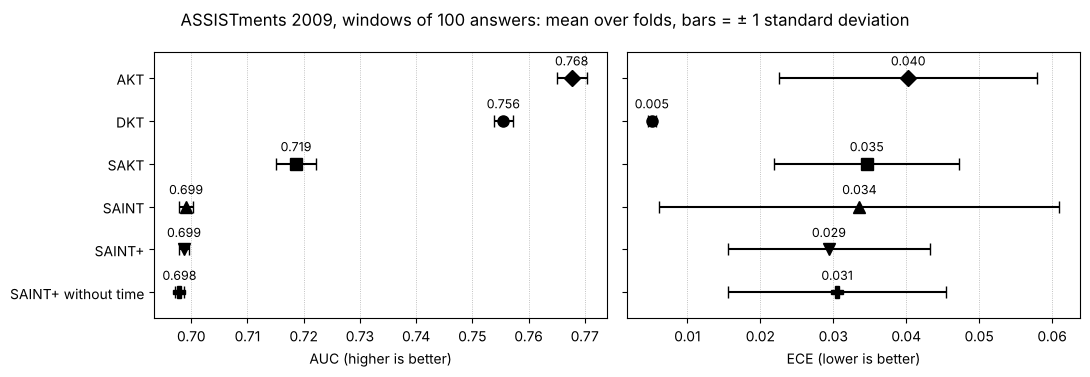

In [3]:
# Chart: AUC and ECE per model with the spread over folds (markers + values, not colour)
order = list(table.index[::-1])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric, label in [(axes[0], "AUC", "AUC (higher is better)"), (axes[1], "ECE", "ECE (lower is better)")]:
    for i, m in enumerate(order):
        mean, sd = table.loc[m, metric], table.loc[m, f"{metric} sd"]
        ax.errorbar(mean, i, xerr=sd, fmt=MARKERS[m], color="black", ms=8, capsize=4)
        ax.annotate(f"{mean:.3f}", (mean, i), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
    ax.set_xlabel(label)
    ax.grid(axis="x", ls=":", lw=0.6)
axes[0].set_yticks(range(len(order)), [LABELS[m] for m in order])
axes[0].set_ylim(-0.6, len(order) - 0.4)
fig.suptitle(f"ASSISTments 2009, windows of {MAIN} answers: mean over folds, bars = ± 1 standard deviation")
fig.tight_layout()
plt.show()

## 2. Sequence-length sensitivity

The same models trained and tested with windows of 50, 100 and 200 answers. Each test answer is predicted from at least half a window of earlier answers when the student has them, so a longer window means more history per prediction.

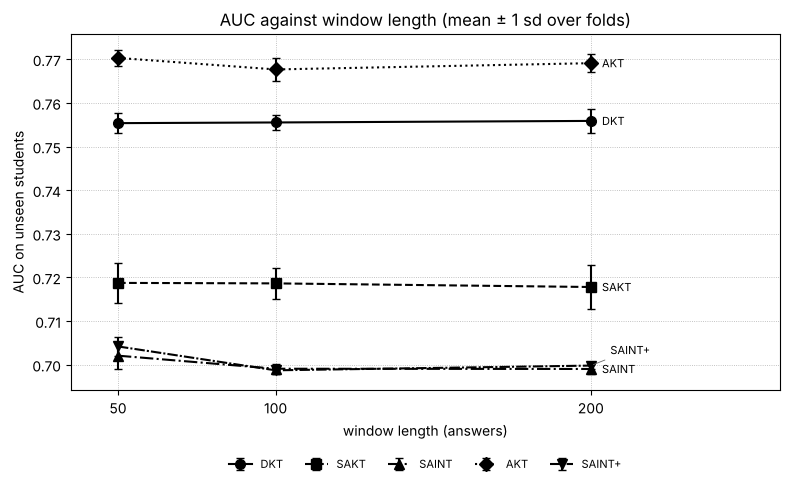

,L = 50,L = 100,L = 200
DKT,0.7554 ± 0.0023,0.7555 ± 0.0017,0.7559 ± 0.0027
SAKT,0.7187 ± 0.0046,0.7186 ± 0.0036,0.7178 ± 0.0052
SAINT,0.7021 ± 0.0031,0.6991 ± 0.0012,0.6990 ± 0.0011
AKT,0.7703 ± 0.0017,0.7677 ± 0.0027,0.7691 ± 0.0021
SAINT+,0.7042 ± 0.0023,0.6987 ± 0.0008,0.6998 ± 0.0007


In [4]:
# Sequence length (concept: how much history the model reads; T042 plans 512 with a sliding window, T048 builds the window)
a = runs[runs.dataset == "assist2009"]
lengths = sorted(a.max_len.unique())
models = [m for m in ORDER if m in set(a.model) and a[a.model == m].max_len.nunique() > 1]
s = a.groupby(["model", "max_len"]).auc.agg(["mean", "std"])
display_tab = pd.DataFrame({f"L = {L}": [pm(*s.loc[(m, L)]) for m in models] for L in lengths},
                           index=[LABELS[m] for m in models])
fig, ax = plt.subplots(figsize=(8, 5))
ends = []
for m in models:
    y = [s.loc[(m, L), "mean"] for L in lengths]
    e = [s.loc[(m, L), "std"] for L in lengths]
    ax.errorbar(lengths, y, yerr=e, marker=MARKERS[m], ls=STYLES[m], color="black", ms=7, capsize=3, label=LABELS[m])
    ends.append((LABELS[m], lengths[-1], y[-1]))
ax.set_xticks(lengths)
ax.set_xlim(lengths[0] - 15, lengths[-1] + 60)
ax.set_xlabel("window length (answers)")
ax.set_ylabel("AUC on unseen students")
ax.set_title("AUC against window length (mean ± 1 sd over folds)")
ax.grid(ls=":", lw=0.6)
label_ends(ax, ends)
legend_below(ax, ncol=5)
fig.tight_layout()
plt.show()
display_tab

## 3. Calibration

One panel per model. Points on the dotted diagonal mean that when the model says 70 %, students are right about 70 % of the time. The size of each bin is written next to its point (thousands of answers), because sparse bins move a lot.

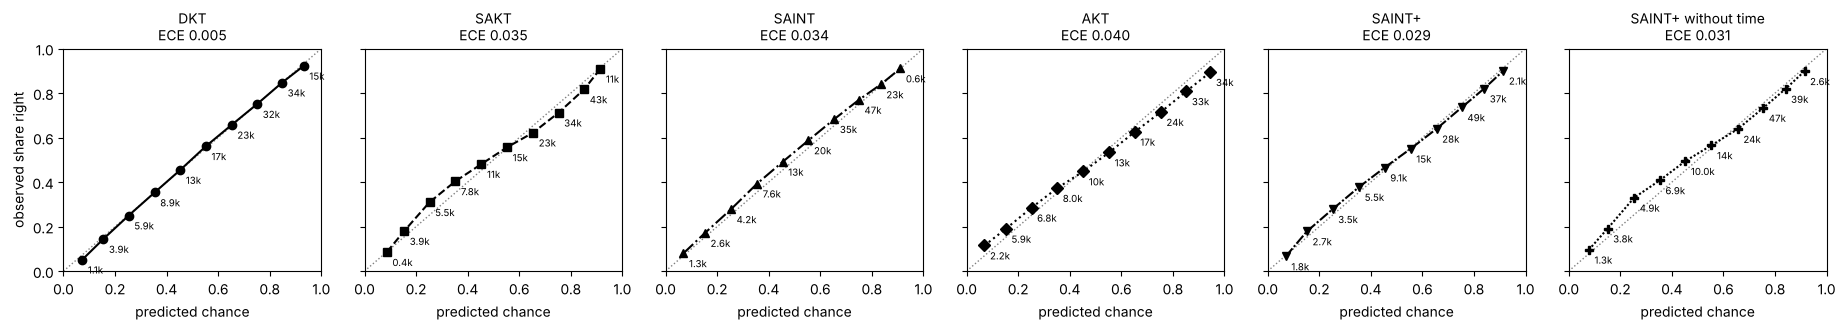

In [5]:
# Reliability diagrams pooled over folds (concept: calibration, T040 / T047 / T050)
c = calib[(calib.dataset == "assist2009") & (calib.max_len == MAIN)].copy()
c["pw"], c["ow"] = c.predicted * c.answers, c.observed * c.answers
pooled = c.groupby(["model", "bin"]).agg(pw=("pw", "sum"), ow=("ow", "sum"), answers=("answers", "sum")).reset_index()
pooled["predicted"], pooled["observed"] = pooled.pw / pooled.answers, pooled.ow / pooled.answers
models = [m for m in ORDER if m in set(pooled.model)]
fig, axes = plt.subplots(1, len(models), figsize=(3.1 * len(models), 3.4), sharey=True)
for ax, m in zip(axes, models):
    p = pooled[pooled.model == m].sort_values("predicted")
    ax.plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
    ax.plot(p.predicted, p.observed, marker=MARKERS[m], ls=STYLES[m], color="black", ms=6)
    for _, r in p.iterrows():
        ax.annotate(f"{r.answers / 1000:.1f}k" if r.answers < 10000 else f"{r.answers / 1000:.0f}k", (r.predicted, r.observed), textcoords="offset points", xytext=(4, -10), fontsize=7)
    ece = table.loc[m, "ECE"] if m in table.index else np.nan
    ax.set_title(f"{LABELS[m]}\nECE {ece:.3f}", fontsize=10)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted chance")
axes[0].set_ylabel("observed share right")
fig.tight_layout()
plt.show()

### 3b. Calibration after Platt scaling

Calibration can be repaired after training without touching the ranking: Platt scaling fits two numbers per model (P' = sigmoid(a · logit P + b)) on the validation students and applies them to the test students. AUC does not change. This was measured in a second run at windows of 100 (`kt_benchmark.py --mode full --datasets assist2009 --lengths 100`), after the first run showed that AKT's raw ECE fails the T047 gate. Training is deterministic, so the second run reproduces the first run's AUCs exactly; the cell below checks it.

In [6]:
# Platt scaling (concept: post-hoc calibration; production: T042 ECE <= 0.05, T047 gate, T050 monitoring)
CAL = "t040_full_assist2009-L100"
cal_runs = pd.read_csv(RESULTS / f"{CAL}_runs.csv")
cal_meta = json.loads((RESULTS / f"{CAL}_meta.json").read_text())
cal_gate = pd.read_csv(RESULTS / f"{CAL}_gate.csv")
cal_calib = pd.read_csv(RESULTS / f"{CAL}_calibration.csv")
both = cal_runs.merge(runs[["dataset", "model", "max_len", "fold", "auc"]], on=["dataset", "model", "max_len", "fold"],
                      suffixes=("", "_first_run"))
print(f"Second run: {len(cal_runs)} training runs in {cal_meta['training_wall_seconds'] / 60:.1f} min, "
      f"code sha256 {cal_meta['code']['code_sha256'][:12]}")
print(f"AUC identical to the first run in {int((both.auc - both.auc_first_run).abs().lt(1e-9).sum())} of {len(both)} runs "
      f"(largest difference {(both.auc - both.auc_first_run).abs().max():.1e})")
g = cal_runs.groupby("model")
cal_tab = pd.DataFrame({
    "AUC": [pm(g.auc.mean()[m], g.auc.std()[m]) for m in g.groups],
    "ECE raw": [pm(g.ece.mean()[m], g.ece.std()[m]) for m in g.groups],
    "ECE after Platt": [pm(g.ece_platt.mean()[m], g.ece_platt.std()[m]) for m in g.groups],
    "accuracy after Platt": [pm(g.accuracy_platt.mean()[m], g.accuracy_platt.std()[m]) for m in g.groups],
    "a (mean)": [g.platt_a.mean()[m] for m in g.groups], "b (mean)": [g.platt_b.mean()[m] for m in g.groups],
}, index=list(g.groups))
cal_tab = cal_tab.loc[[m for m in ORDER if m in cal_tab.index]]
cal_tab.index = [LABELS[m] for m in cal_tab.index]
cal_tab.round(3)

Second run: 18 training runs in 11.0 min, code sha256 d8ae9f6780e8
AUC identical to the first run in 18 of 18 runs (largest difference 0.0e+00)


,AUC,ECE raw,ECE after Platt,accuracy after Platt,a (mean),b (mean)
DKT,0.7555 ± 0.0017,0.0051 ± 0.0006,0.0085 ± 0.0050,0.7333 ± 0.0061,1.027,-0.042
SAKT,0.7186 ± 0.0036,0.0346 ± 0.0127,0.0134 ± 0.0032,0.7105 ± 0.0092,0.865,-0.010
SAINT,0.6991 ± 0.0012,0.0336 ± 0.0274,0.0062 ± 0.0037,0.7110 ± 0.0112,1.032,0.078
AKT,0.7677 ± 0.0027,0.0403 ± 0.0177,0.0097 ± 0.0089,0.7406 ± 0.0037,0.827,-0.056
SAINT+,0.6987 ± 0.0008,0.0294 ± 0.0138,0.0109 ± 0.0054,0.7115 ± 0.0114,0.963,-0.049
SAINT+ without time,0.6979 ± 0.0008,0.0305 ± 0.0150,0.0107 ± 0.0054,0.7091 ± 0.0099,0.897,0.015


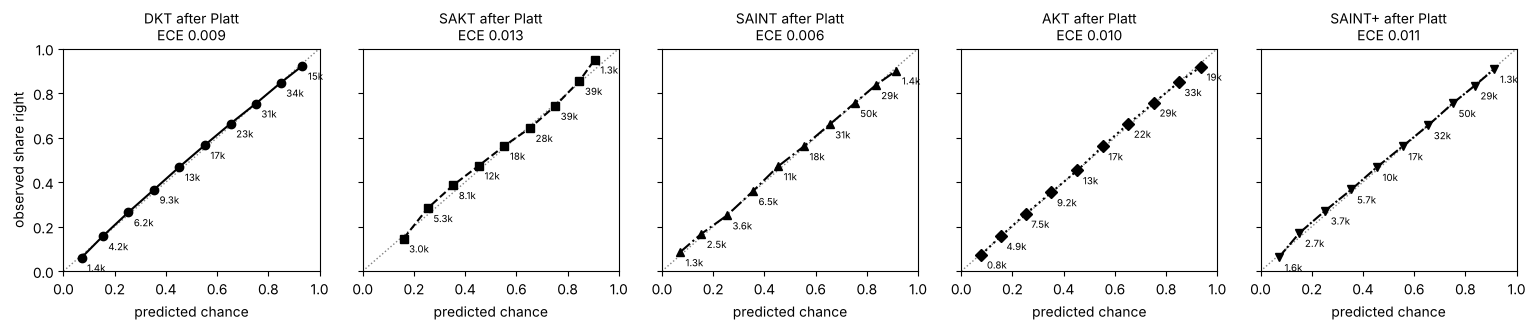

In [7]:
# Reliability diagrams after Platt scaling, pooled over folds
c = cal_calib[cal_calib.calibration == "platt"].copy()
c["pw"], c["ow"] = c.predicted * c.answers, c.observed * c.answers
pooled = c.groupby(["model", "bin"]).agg(pw=("pw", "sum"), ow=("ow", "sum"), answers=("answers", "sum")).reset_index()
pooled["predicted"], pooled["observed"] = pooled.pw / pooled.answers, pooled.ow / pooled.answers
models = [m for m in ORDER if m in set(pooled.model) and m != "saint_plus_notime"]
fig, axes = plt.subplots(1, len(models), figsize=(3.1 * len(models), 3.4), sharey=True)
for ax, m in zip(axes, models):
    p = pooled[pooled.model == m].sort_values("predicted")
    ax.plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
    ax.plot(p.predicted, p.observed, marker=MARKERS[m], ls=STYLES[m], color="black", ms=6)
    for _, r in p.iterrows():
        ax.annotate(f"{r.answers / 1000:.1f}k" if r.answers < 10000 else f"{r.answers / 1000:.0f}k",
                    (r.predicted, r.observed), textcoords="offset points", xytext=(4, -10), fontsize=7)
    ax.set_title(f"{LABELS[m]} after Platt\nECE {cal_runs[cal_runs.model == m].ece_platt.mean():.3f}", fontsize=10)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted chance")
axes[0].set_ylabel("observed share right")
fig.tight_layout()
plt.show()

In [8]:
# The T047 gate again, raw and after Platt scaling of both models (fold-paired, against DKT)
gg = cal_gate.copy()
gg["challenger"] = gg.challenger.map(LABELS)
gg["ECE compared"] = gg.ece_metric.map({"ece": "raw", "ece_platt": "after Platt"})
gg[["ECE compared", "challenger", "folds", "delta_auc_mean", "delta_auc_std", "delta_ece_mean", "worst_slice",
    "worst_slice_delta_auc", "passes_t047_gate"]].round(4)

,ECE compared,challenger,folds,delta_auc_mean,delta_auc_std,delta_ece_mean,worst_slice,worst_slice_delta_auc,passes_t047_gate
0,raw,AKT,3,0.0122,0.0040,0.0352,answers 2-10,0.0020,False
1,raw,SAINT,3,-0.0564,0.0016,0.0285,answers 51+,-0.0650,False
2,raw,SAINT+,3,-0.0568,0.0010,0.0243,answers 51+,-0.0665,False
3,raw,SAINT+ without time,3,-0.0576,0.0015,0.0254,answers 51+,-0.0668,False
4,raw,SAKT,3,-0.0369,0.0022,0.0295,answers 51+,-0.0381,False
5,after Platt,AKT,3,0.0122,0.0040,0.0011,answers 2-10,0.0020,True
6,after Platt,SAINT,3,-0.0564,0.0016,-0.0024,answers 51+,-0.0650,False
7,after Platt,SAINT+,3,-0.0568,0.0010,0.0024,answers 51+,-0.0665,False
8,after Platt,SAINT+ without time,3,-0.0576,0.0015,0.0021,answers 51+,-0.0668,False
9,after Platt,SAKT,3,-0.0369,0.0022,0.0049,answers 51+,-0.0381,False


## 4. Slices and the T047 gate rule against DKT

Slices by position in the student's history: answers 2–10 are the cold start (where the IRT estimator of T043 will help), answers 51 and later are students with a long history. ASSISTments has no accommodation data, so the accommodation slices are measured on the simulator in section 5.

The T047 gate rule says a challenger is better than the champion only if its AUC is at least 0.005 higher, no slice loses more than 0.01 AUC, and ECE is not worse by more than 0.01. Differences are paired by fold (same test students).

In [9]:
# AUC per slice (concept: fairness and cold-start slices, T047)
sl = slices[(slices.dataset == "assist2009") & (slices.max_len == MAIN)]
slice_order = ["answers 2-10", "answers 11-50", "answers 51+"]
t = sl.groupby(["model", "slice"]).agg(auc=("auc", "mean"), sd=("auc", "std"), ece=("ece", "mean"),
                                       n=("n_predictions", "mean")).reset_index()
models = [m for m in ORDER if m in set(t.model)]
auc_tab = pd.DataFrame({s_: [pm(*t[(t.model == m) & (t.slice == s_)][["auc", "sd"]].iloc[0]) for m in models]
                        for s_ in slice_order}, index=[LABELS[m] for m in models])
n_tab = t[t.model == "dkt"].set_index("slice").n.reindex(slice_order).round(0).astype(int)
print("Test answers per fold in each slice:", n_tab.to_dict())
auc_tab

Test answers per fold in each slice: {'answers 2-10': 6117, 'answers 11-50': 13654, 'answers 51+': 31626}


,answers 2-10,answers 11-50,answers 51+
DKT,0.7671 ± 0.0038,0.7733 ± 0.0052,0.7437 ± 0.0042
SAKT,0.7363 ± 0.0004,0.7354 ± 0.0019,0.7056 ± 0.0062
SAINT,0.7184 ± 0.0104,0.7291 ± 0.0075,0.6787 ± 0.0064
AKT,0.7692 ± 0.0057,0.7842 ± 0.0032,0.7587 ± 0.0031
SAINT+,0.7249 ± 0.0047,0.7289 ± 0.0095,0.6772 ± 0.0055
SAINT+ without time,0.7238 ± 0.0032,0.7272 ± 0.0087,0.6769 ± 0.0059


In [10]:
# The T047 gate, fold-paired, against the DKT baseline
gt = gate[(gate.dataset == "assist2009")].copy()
gt["challenger"] = gt.challenger.map(LABELS)
gt[["max_len", "challenger", "folds", "delta_auc_mean", "delta_auc_std", "delta_ece_mean", "worst_slice",
    "worst_slice_delta_auc", "passes_t047_gate"]].round(4).sort_values(["max_len", "delta_auc_mean"], ascending=[True, False])

,max_len,challenger,folds,delta_auc_mean,delta_auc_std,delta_ece_mean,worst_slice,worst_slice_delta_auc,passes_t047_gate
0,50,AKT,3,0.0149,0.0039,0.0226,answers 2-10,0.0019,False
3,50,SAKT,3,-0.0366,0.0024,0.0295,answers 51+,-0.0400,False
2,50,SAINT+,3,-0.0512,0.0014,0.0153,answers 51+,-0.0586,False
1,50,SAINT,3,-0.0533,0.0022,0.0156,answers 51+,-0.0604,False
4,100,AKT,3,0.0122,0.0040,0.0352,answers 2-10,0.0020,False
8,100,SAKT,3,-0.0369,0.0022,0.0295,answers 51+,-0.0381,False
5,100,SAINT,3,-0.0564,0.0016,0.0285,answers 51+,-0.0650,False
6,100,SAINT+,3,-0.0568,0.0010,0.0243,answers 51+,-0.0665,False
7,100,SAINT+ without time,3,-0.0576,0.0015,0.0254,answers 51+,-0.0668,False
9,200,AKT,3,0.0132,0.0048,0.0347,answers 2-10,0.0014,False


## 5. Time features and accommodations

SAINT+ adds two time signals to SAINT: how long the previous answer took (elapsed time) and the gap since the previous answer (lag time). ASSISTments 2009 has elapsed time but no timestamps, so on it SAINT+ uses elapsed time only. The simulator has both, and it has students with an official time multiplier (x1.33 or x1.5) and an assistive mode, so it is where the accommodation slices are checked. The simulator is synthetic: it tells us whether a model can be unfair to students with extra time, not how large the effect is for real students.

In [11]:
# Does elapsed time help on real data? Paired by fold (concept: SAINT+ time embeddings, T042)
a = runs[(runs.dataset == "assist2009") & (runs.max_len == MAIN)].pivot_table(index="fold", columns="model", values=["auc", "ece"])
if "saint_plus_notime" in a["auc"]:
    d = a["auc"]["saint_plus"] - a["auc"]["saint_plus_notime"]
    print(f"ASSISTments 2009: SAINT+ {pm(a['auc']['saint_plus'].mean(), a['auc']['saint_plus'].std())}, "
          f"without time {pm(a['auc']['saint_plus_notime'].mean(), a['auc']['saint_plus_notime'].std())}; "
          f"paired gain from elapsed time {d.mean():+.4f} ± {d.std():.4f} AUC")

ASSISTments 2009: SAINT+ 0.6987 ± 0.0008, without time 0.6979 ± 0.0008; paired gain from elapsed time +0.0008 ± 0.0005 AUC


In [12]:
# Simulator: overall and accommodation slices (concept: fairness for accommodations, T047, T148)
sim = runs[runs.dataset == "simulated"]
sim_tab = None
if len(sim):
    ss = slices[slices.dataset == "simulated"]
    cols = ["no accommodation", "extra time (x1.33 or x1.5)", "assistive mode"]
    models = [m for m in ORDER if m in set(sim.model)]
    rows = []
    for m in models:
        r = sim[sim.model == m]
        row = {"model": LABELS[m], "AUC": pm(r.auc.mean(), r.auc.std()), "ECE": pm(r.ece.mean(), r.ece.std())}
        for c_ in cols:
            x = ss[(ss.model == m) & (ss.slice == c_)]
            row[f"AUC {c_}"] = f"{x.auc.mean():.4f}"
            row[f"ECE {c_}"] = f"{x.ece.mean():.4f}"
        x0 = ss[(ss.model == m) & (ss.slice == cols[0])].set_index("fold")
        x1 = ss[(ss.model == m) & (ss.slice == cols[1])].set_index("fold")
        row["AUC gap extra time - none"] = f"{(x1.auc - x0.auc).mean():+.4f}"
        rows.append(row)
    n = ss[(ss.model == "dkt")].groupby("slice").n_predictions.mean().round(0).astype(int)
    print("Simulated test answers per fold in each slice:", {k: int(n[k]) for k in cols if k in n})
    sim_tab = pd.DataFrame(rows).set_index("model")
sim_tab

Simulated test answers per fold in each slice: {'no accommodation': 12138, 'extra time (x1.33 or x1.5)': 2142, 'assistive mode': 754}


,AUC,ECE,AUC no accommodation,ECE no accommodation,AUC extra time (x1.33 or x1.5),ECE extra time (x1.33 or x1.5),AUC assistive mode,ECE assistive mode,AUC gap extra time - none
model,,,,,,,,,
DKT,0.6556 ± 0.0020,0.0117 ± 0.0047,0.6573,0.0113,0.6476,0.0207,0.6567,0.0374,-0.0097
SAKT,0.6401 ± 0.0059,0.0177 ± 0.0060,0.6422,0.0159,0.6285,0.0307,0.6328,0.0554,-0.0137
SAINT,0.5623 ± 0.0018,0.0196 ± 0.0063,0.5607,0.0200,0.5661,0.0229,0.5576,0.0338,+0.0055
AKT,0.6801 ± 0.0069,0.0179 ± 0.0126,0.6808,0.0189,0.6771,0.0226,0.6755,0.0438,-0.0037
SAINT+,0.5606 ± 0.0033,0.0218 ± 0.0150,0.5588,0.0223,0.5650,0.0275,0.5437,0.0387,+0.0062
SAINT+ without time,0.5600 ± 0.0015,0.0119 ± 0.0037,0.5582,0.0122,0.5647,0.0183,0.5492,0.0282,+0.0065
SAINT+ time / multiplier,0.5608 ± 0.0035,0.0314 ± 0.0104,0.5590,0.0312,0.5650,0.0384,0.5440,0.0321,+0.0060


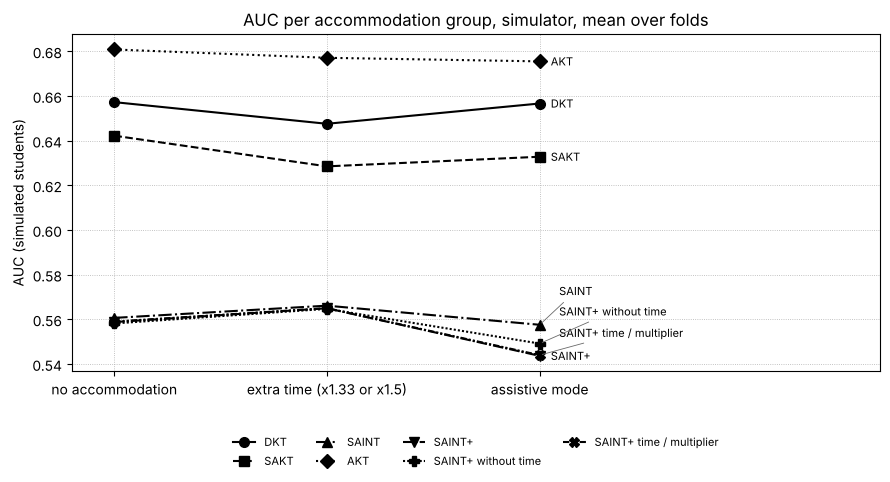

In [13]:
# Chart: AUC per accommodation group on the simulator (markers + values)
if len(sim):
    fig, ax = plt.subplots(figsize=(9, 5))
    groups = cols
    ends = []
    for i, m in enumerate(models):
        y = [ss[(ss.model == m) & (ss.slice == g_)].auc.mean() for g_ in groups]
        ax.plot(range(len(groups)), y, marker=MARKERS[m], ls=STYLES[m], color="black", ms=7, label=LABELS[m])
        ends.append((LABELS[m], len(groups) - 1, y[-1]))
    ax.set_xticks(range(len(groups)), groups)
    ax.set_xlim(-0.2, len(groups) + 0.6)
    ax.set_ylabel("AUC (simulated students)")
    ax.set_title("AUC per accommodation group, simulator, mean over folds")
    ax.grid(ls=":", lw=0.6)
    label_ends(ax, ends, min_gap=0.06)
    legend_below(ax, ncol=4)
    fig.tight_layout()
    plt.show()

## 6. CPU inference latency

One forward pass over a full window predicts the next answer of every student in the batch, as the online service will (T046, T048). Latency is the median over many passes on this machine's CPU, with PyTorch using one thread or four. GPU latency is pending: there is no GPU before the cloud (S8+), and no number is invented for it.

In [14]:
# Latency table (concept: inference cost, T046 serving, T048 sequence builder)
lat = latency[latency.device == "cpu"].copy()
lat["model"] = lat.model.map(LABELS)
pivot = lat.pivot_table(index=["model", "max_len"], columns=["batch", "threads"], values="ms_per_prediction")
pivot.columns = [f"batch {int(b)}, {int(t)} thread{'s' if t > 1 else ''}" for b, t in pivot.columns]
gpu = latency[latency.device == "gpu"]
print(f"GPU: {gpu.note.iloc[0] if len(gpu) else 'not measured'}")
print("ms per prediction (median); one prediction = next-answer probability for one student")
pivot.round(3)

GPU: pending: no GPU before the cloud (S8+)
ms per prediction (median); one prediction = next-answer probability for one student


batch 1, 1 thread  batch 1, 4 threads  batch 64, 1 thread  batch 64, 4 threads
model  max_len                                                                                
AKT    50                   2.260               2.240               0.774                0.224
       100                  3.774               2.995               2.887                0.874
       200                  9.223               4.744              21.534                7.642
DKT    50                   0.228               0.321               0.048                0.042
       100                  0.357               0.551               0.095                0.047
       200                  0.918               0.873               0.187                0.082
SAINT  50                   1.502               1.582               0.458                0.155
       100                  2.574               1.996               1.107                0.353
       200                  4.652               3.214               7.292                2.201
SAINT+ 50                   1.959               1.542               0.636                0.210
       100                  3.017               2.161               1.784                0.531
       200                  7.324               4.142              10.219                3.028
SAKT   50                   0.526               0.527               0.144                0.049
       100                  0.890               0.808               0.381                0.111
       200                  1.839               1.204               2.281                0.709

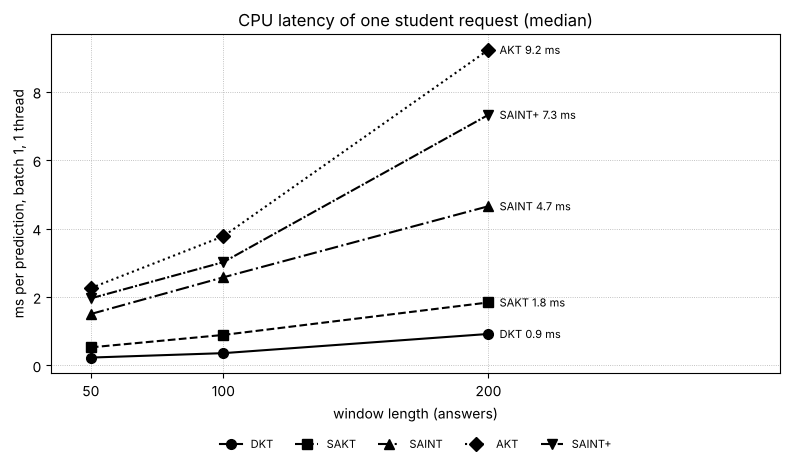

In [15]:
# Chart: ms per prediction against window length, batch 1 (a single student request), one thread
lat1 = latency[(latency.device == "cpu") & (latency.batch == 1) & (latency.threads == 1)]
fig, ax = plt.subplots(figsize=(8, 4.8))
ends = []
for m in [m for m in ORDER if m in set(lat1.model)]:
    r = lat1[lat1.model == m].sort_values("max_len")
    ax.plot(r.max_len, r.ms_per_prediction, marker=MARKERS[m], ls=STYLES[m], color="black", ms=7, label=LABELS[m])
    ends.append((f"{LABELS[m]} {r.ms_per_prediction.iloc[-1]:.1f} ms", r.max_len.iloc[-1], r.ms_per_prediction.iloc[-1]))
ax.set_xticks(sorted(lat1.max_len.unique()))
ax.set_xlim(lat1.max_len.min() - 15, lat1.max_len.max() + 110)
ax.set_xlabel("window length (answers)")
ax.set_ylabel("ms per prediction, batch 1, 1 thread")
ax.set_title("CPU latency of one student request (median)")
ax.grid(ls=":", lw=0.6)
label_ends(ax, ends)
legend_below(ax, ncol=5)
fig.tight_layout()
plt.show()

## 7. Training curves

Validation AUC after each epoch (fold 0, windows of 100). Early stopping keeps the best epoch; a curve that is still rising at the last epoch means the model might gain from longer training.

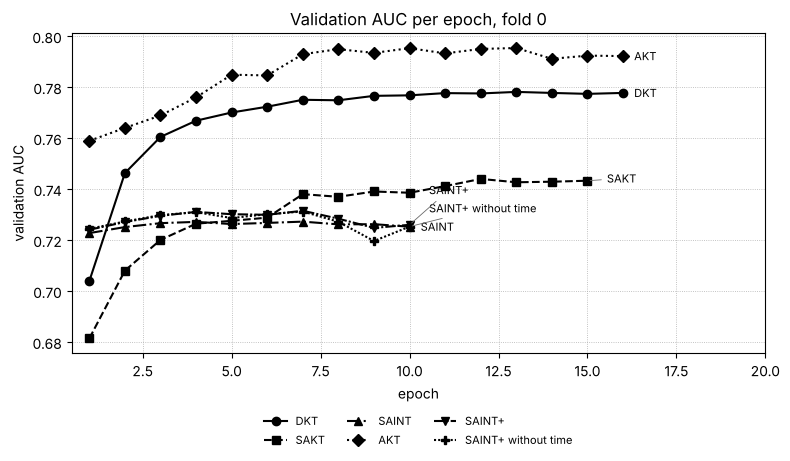

Runs whose best epoch was the last allowed epoch (20): 3 of 69 {('simulated', 'akt'): 2, ('simulated', 'sakt'): 1}


In [16]:
# Validation AUC per epoch (concept: early stopping on held-out students)
h = history[(history.dataset == "assist2009") & (history.max_len == MAIN) & (history.fold == 0)]
fig, ax = plt.subplots(figsize=(8, 4.8))
ends = []
for m in [m for m in ORDER if m in set(h.model)]:
    r = h[h.model == m]
    ax.plot(r.epoch, r.valid_auc, marker=MARKERS[m], ls=STYLES[m], color="black", ms=6, label=LABELS[m])
    ends.append((LABELS[m], r.epoch.iloc[-1], r.valid_auc.iloc[-1]))
ax.set_xlabel("epoch")
ax.set_ylabel("validation AUC")
ax.set_xlim(0.5, h.epoch.max() + 4)
ax.grid(ls=":", lw=0.6)
ax.set_title("Validation AUC per epoch, fold 0")
label_ends(ax, ends)
legend_below(ax, ncol=3)
fig.tight_layout()
plt.show()
stopped_at_max = runs[(runs.best_epoch == meta["config"]["max_epochs"])]
print(f"Runs whose best epoch was the last allowed epoch ({meta['config']['max_epochs']}): {len(stopped_at_max)} of {len(runs)}",
      stopped_at_max.groupby(["dataset", "model"]).size().to_dict())

## Findings

All numbers below are printed by the cells above (ASSISTments 2009 unless stated; mean ± standard deviation over 3 folds of 726 unseen students each; differences are paired by fold).

1. **AKT ranks answers best, at every window length.** With windows of 100: AKT 0.7677 ± 0.0027, DKT 0.7555 ± 0.0017, SAKT 0.7186 ± 0.0036, SAINT 0.6991 ± 0.0012, SAINT+ 0.6987 ± 0.0008. AKT beats DKT by +0.0122 ± 0.0040 AUC (+0.0149 with windows of 50, +0.0132 with 200), and its lead grows with history: +0.002 on answers 2–10, +0.011 on answers 11–50, +0.015 on answers 51 and later.
2. **SAINT and SAINT+ are clearly behind on this data**: about 0.057 AUC below DKT and 0.069 below AKT, losing most on long histories (answers 51+). A likely reason, not tested here: they learn 64 numbers per item for 15,901 items with about 16 answers each, while AKT learns one difficulty number per item.
3. **Time features barely help.** SAINT+ with elapsed time against the same model without time: +0.0008 ± 0.0005 AUC on ASSISTments 2009 (positive in all 3 folds, far below the +0.005 the T047 gate asks), and +0.0007 ± 0.0021 on the simulator, which also has lag time.
4. **Longer windows do not help on this data.** No model gains from 200 answers over 50 (AKT 0.7703, 0.7677 and 0.7691 for 50, 100 and 200; DKT 0.7554, 0.7555 and 0.7559); SAINT and SAINT+ are slightly better with 50. Half the students have 24 answers or fewer.
5. **Calibration decides the T047 gate.** Raw, AKT's ECE (0.0403 ± 0.0177) is worse than DKT's (0.0051 ± 0.0006) by more than 0.01, so AKT fails the gate at every length. After Platt scaling fitted on the validation students, AKT's ECE is 0.0097 and DKT's 0.0085, and AKT passes the gate against DKT (AUC +0.0122, worst slice +0.0020, ECE +0.0011). Against raw DKT, calibrated AKT is +0.0045 ECE on average but +0.0143 on one fold: a calibration fitted on 290 students is not yet stable.
6. **Accommodations (simulator only).** On simulated students AKT also leads (0.6801 ± 0.0069 against DKT 0.6556 ± 0.0020) and passes the gate against DKT with raw ECE. No model shows an AUC gap between students with extra time and the others larger than its spread over folds (AKT −0.004 ± 0.012, DKT −0.010 ± 0.014). With about 2,100 extra-time answers per fold this rules out only a large unfairness; it does not prove fairness.
7. **Cost.** AKT is the most expensive model to run: one student request with windows of 100 takes a median 3.8 ms on one CPU thread (p95 4.4 ms), against 0.36 ms for DKT; with windows of 200 it takes 9.2 ms. That fits a 50 ms budget per request, but it is about ten times DKT's compute. GPU latency is pending (cloud, S8+).

These findings feed the proposal in [ADR 0007](../../docs/architecture/decisions/0007-knowledge-tracing-model.md): AKT with Platt calibration and windows of 100, DKT as the fallback, and a re-check on Kuizi pilot data in T239. The product owner decides.